# Electrically Synaptically coupled neurons

We consider two identical neurons coupled by a gap junction

$C \frac{dV_1(t)}{dt}\ = \ G_{leak} (E_{leak} - V_1) + G_{Na} m_1^3 h_1 (E_{Na} - V_1) + G_{K} n_1^4 (E_{K} - V_1) + I - G_{gap} (V_1 - V_2)$

$\frac{dn_1}{dt}\ = \ \alpha_n (1 - n_1) - \beta_n n_1$

$\frac{dm_1}{dt}\ = \ \alpha_m (1 - m_1) - \beta_m m_1$

$\frac{dh_1}{dt}\ = \ \alpha_h (1 - h_1) - \beta_h h_1$

and also

$C \frac{dV_2(t)}{dt}\ = \ G_{leak} (E_{leak} - V_2) + G_{Na} m_2^3 h_2 (E_{Na} - V_2) + G_{K} n_2^4 (E_{K} - V_2) + I - G_{gap} (V_2 - V_1)$

$\frac{dn_2}{dt}\ = \ \alpha_n (1 - n_2) - \beta_n n_2$

$\frac{dm_2}{dt}\ = \ \alpha_m (1 - m_2) - \beta_m m_2$

$\frac{dh_2}{dt}\ = \ \alpha_h (1 - h_2) - \beta_h h_2$

In [1]:
# @title Parameters of the simulation
import numpy as np
import matplotlib.pyplot as plt

T      = 300.    # Maximal lifetime of the simulation [ms]
Δt     = 0.01    # Integration time step [ms] - WATCH OUT! DO NOT INCREASE!

C      = 0.010   # This is the membrane (specific) capacitance [uF/mm^2]
gnamax = 1.2     # Max (specific) sodium conductance [mS/mm^2]
gkmax  = 0.36    # Max (specific) potassium conductance [mS/mm^2]
gl     = 0.003   # Max (specific) leak conductance [mS/mm^2]

Ena    = 50.    # Reversal potential for sodium currents [mV]
Ek     = -77.    # Reversal potential for potassium currents [mV]
El     = -54.387 # Reversal potential for leak currents [mV]

ggap   = 0.1     # (specific) coupling conductance [mS/mm^2]

# Calculate the number of time steps using the total time and time step
N = int(T / Δt)  # Ensure N is an integer

# Generate the time array using N as the num argument
time = np.linspace(0, T, N)        # Array containing the "time" axis [ms]

In [2]:
# @title Functions to simulate the two (coupled) HH models simultaneously
def coupled_HH(I, Vo1, Vo2):
  # Initialize the variables
  W1 = np.zeros(N)  # Array containing V1 as the time goes by
  W2 = np.zeros(N)  # Array containing V2 as the time goes by
  Nspikes1 = 0      # Counter for the number of spikes
  Nspikes2 = 0      # Counter for the number of spikes

  # Initial conditions:
  V1      = Vo1
  αm = 0.1 * (V1+40.) / (1. - np.exp(-(V1+40.)/10.))
  βm  = 4. * np.exp(-0.0556 * (V1+65))

  αn = 0.01 * (V1+55) / (1. - np.exp(-(V1+55.)/10.))
  βn = 0.125 * np.exp(-(V1+65.)/80.)

  αh = 0.07 * np.exp(-0.05*(V1+65.))
  βh = 1. / (1. + np.exp(-0.1*(V1+35.)))

  m1      = αm / (αm + βm)
  h1      = αh / (αh + βh)
  n1      = αn / (αn + βn)

  V2      = Vo2
  αm = 0.1 * (V2+40.) / (1. - np.exp(-(V2+40.)/10.))
  βm  = 4. * np.exp(-0.0556 * (V2+65))

  αn = 0.01 * (V2+55) / (1. - np.exp(-(V2+55.)/10.))
  βn = 0.125 * np.exp(-(V2+65.)/80.)

  αh = 0.07 * np.exp(-0.05*(V2+65.))
  βh = 1. / (1. + np.exp(-0.1*(V2+35.)))

  m2      = αm / (αm + βm)
  h2      = αh / (αh + βh)
  n2      = αn / (αn + βn)

  tmp1    = 0        # For the peak detection
  tmp2    = 0        # For the peak detection

  # Euler method ---------------------------------------------------------------
  for k in range(1,N): # Loop over each discrete step for time t
     # Kinetic rates are expressed in msec
      αm = 0.1 * (V1 + 40.) / (1. - np.exp(-(V1 + 40.) / 10.))
      βm  = 4. * np.exp(-0.0556 * (V1 + 65))

      αn = 0.01 * (V1 + 55) / (1. - np.exp(-(V1 + 55.)/10.))
      βn = 0.125 * np.exp(-(V1 + 65.) / 80.)

      αh = 0.07 * np.exp(-0.05*(V1 + 65.))
      βh = 1. / (1. + np.exp(-0.1*(V1 + 35.)))

      n1     = n1 + Δt * (αn * (1-n1) - βn * n1)     # Euler forward method
      m1     = m1 + Δt * (αm * (1-m1) - βm * m1)     # Euler forward method
      h1     = h1 + Δt * (αh * (1-h1) - βh * h1)     # Euler forward method

      αm = 0.1 * (V2 + 40.) / (1. - np.exp(-(V2 + 40.) / 10.))
      βm  = 4. * np.exp(-0.0556 * (V2 + 65))

      αn = 0.01 * (V2 + 55) / (1. - np.exp(-(V2 + 55.)/10.))
      βn = 0.125 * np.exp(-(V2 + 65.) / 80.)

      αh = 0.07 * np.exp(-0.05*(V2 + 65.))
      βh = 1. / (1. + np.exp(-0.1*(V2 + 35.)))

      n2     = n2 + Δt * (αn * (1-n2) - βn * n2)     # Euler forward method
      m2     = m2 + Δt * (αm * (1-m2) - βm * m2)     # Euler forward method
      h2     = h2 + Δt * (αh * (1-h2) - βh * h2)     # Euler forward method


      Ina1   = gnamax * m1**3 * h1 * (Ena - V1)       # By definition
      Ik1    = gkmax  * n1**4 * (Ek - V1)			# By definition
      Ileak1 = gl     * (El - V1)					# By definition

      Ina2   = gnamax * m2**3 * h2 * (Ena - V2)       # By definition
      Ik2    = gkmax  * n2**4 * (Ek - V2)			# By definition
      Ileak2 = gl     * (El - V2)					# By definition

      Igap = ggap     * (V1 - V2)					# By definition

      V1     = V1 + Δt/C * (Ina1 + Ik1 + Ileak1 + I - Igap)  # Euler forward method
      V2     = V2 + Δt/C * (Ina2 + Ik2 + Ileak2 + I + Igap)  # Euler forward method

      W1[k]  = V1; # Let's write the current V1 inside a new element of W1[]
      W2[k]  = V2; # Let's write the current V2 inside a new element of W2[]

      if (tmp1==0) and (V1>-10):     # Detection of a "peak", with positive derivative
        tmp1 = 1;
        Nspikes1 = Nspikes1 + 1;
      elif (tmp1==1) and (V1<-10): # if negative derivative, ignore it
        tmp1 = 0;

      if (tmp2==0) and (V2>-10):     # Detection of a "peak", with positive derivative
        tmp2 = 1;
        Nspikes2 = Nspikes2 + 1;
      elif (tmp2==1) and (V2<-10): # if negative derivative, ignore it
        tmp2 = 0;
    # ----------------------------------------------------------------------------

  freq1 = np.round(1000. * Nspikes1 / T)
  freq2 = np.round(1000. * Nspikes2 / T)

  return W1, W2, freq1, freq2

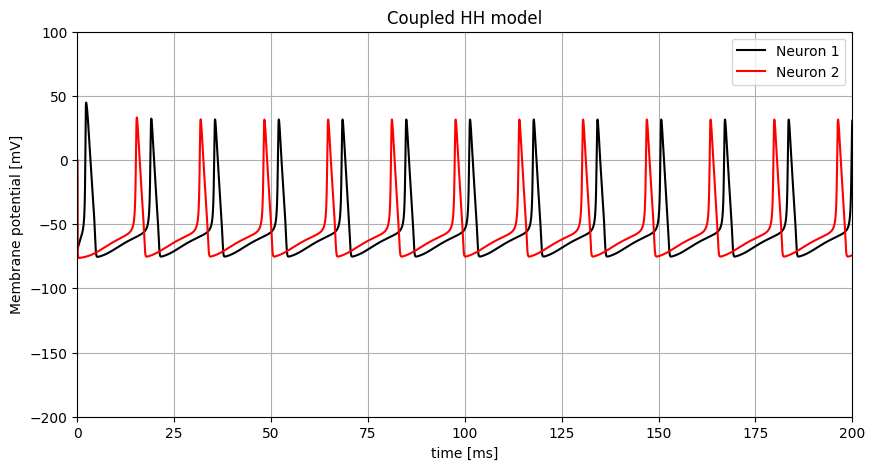

In [3]:
# @title After running this cell manually, it will auto-run if you change the selected value. { run: "auto" }
T = 200.
# Calculate the number of time steps using the total time and time step
N = int(T / Δt)  # Ensure N is an integer


I0 = 0.0745
ggap = 0 #@param {type:"slider", min:0.0, max:0.001, step:0.0001}

# Generate the time array using N as the num argument
time = np.linspace(0, T, N)        # Array containing the "time" axis [ms]

W1, W2, freq1, freq2 =  coupled_HH(I0, -70, 0)

fig = plt.figure(figsize=(10, 5))  # Create the figure and assign to fig
plt.plot(time, W1, label='Neuron 1', color='black', linestyle='-')
plt.plot(time, W2, label='Neuron 2', color='red', linestyle='-')

plt.xlabel('time [ms]')
plt.ylabel('Membrane potential [mV]')
plt.title('Coupled HH model')
plt.xlim([0, T])
plt.ylim([-200, 100])
plt.grid(True)
plt.legend()
plt.show()


In [6]:
# @title Generate and playback a video of the "state-space" trajectories (launch once)

from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np

# Configure the animation plotting with a single axes
fig, ax = plt.subplots(figsize=(5, 5))

dV1_dt = np.diff(W1) / Δt
dV2_dt = np.diff(W2) / Δt

# Speed up background rendering by downsampling the static trajectory lines (every 5th point)
ax.plot(W1[::5], dV1_dt[::5], color='black', alpha=0.1, label='State-space Trajectory')
ax.set_xlabel('Voltage V [mV]')
ax.set_ylabel('dV/dt [mV/ms]')
ax.set_title('Phase Space Synchronization: dV/dt vs V')
ax.grid(True)

# Initialize the moving state indicators (dots)
point1, = ax.plot([], [], 'ko', markersize=10, label='Neuron 1 Position')
point2, = ax.plot([], [], 'ro', markersize=10, label='Neuron 2 Position')

ax.legend(loc='upper right')
time_text = ax.text(0.05, 0.95, '', transform=ax.transAxes, fontsize=12, verticalalignment='top')

# Let's change the axis limits
plt.xlim([-80, 40])
plt.ylim([-70, 300])

def init():
    point1.set_data([], [])
    point2.set_data([], [])
    time_text.set_text('')
    return point1, point2, time_text

# Decrease step size to capture more detailed points, making the video slower and smoother
frame_indices = []
k = 0
while k < len(time):
    frame_indices.append(k)
    rate = max(abs(dV1_dt[k]), abs(dV2_dt[k]))
    # Captured more frames by halving step sizes
    step = max(3, int(60 / (1 + 0.05 * rate)))
    k += step

def animate(idx):
    v1, dv1 = W1[idx], dV1_dt[idx]
    v2, dv2 = W2[idx], dV2_dt[idx]

    # Update marker positions
    point1.set_data([v1], [dv1])
    point2.set_data([v2], [dv2])

    time_text.set_text(f'Time: {time[idx]:.1f} ms / {T} ms')
    return point1, point2, time_text

# Increased interval to 150ms for a much slower, readable playback pace
anim = FuncAnimation(fig, animate, init_func=init, frames=frame_indices, interval=150, blit=True)
plt.close()

# Display the animation as an HTML5 video
HTML(anim.to_html5_video())